In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from config import PROCESSED
from utils import load_bg, load_stations, group_summary

pd.set_option("display.float_format", "{:,.2f}".format)

Among currently operating stations inside the city, do stations in higher-income tracts have earlier recorded opening dates? The inventory lists only operating stations, so closed stations are not included.

In [2]:
st = load_stations()
st = st[st.in_city].copy()
tr = pd.read_csv(PROCESSED / "tracts_income.csv", dtype={"tract_geoid": str})
bg_all = load_bg(universe_only=False)[["tract_geoid", "geometry"]].to_crs(st.crs)
st = gpd.sjoin(st, bg_all, how="left", predicate="within").merge(tr, on="tract_geoid", how="left")
inc_med = tr.med_income.median()
st["income_grp"] = np.where(st.med_income >= inc_med, "Higher income", "Lower income")
st.loc[st.med_income.isna(), "income_grp"] = "Income missing"
st.groupby("income_grp").agg(stations=("id", "size"),
                             missing_date_share=("open_date", lambda s: s.isna().mean()),
                             median_open=("open_date", "median"),
                             l2_ports=("ev_level2_evse_num", "sum"),
                             dcfc_ports=("ev_dc_fast_num", "sum"))

,stations,missing_date_share,median_open,l2_ports,dcfc_ports
income_grp,,,,,
Higher income,114,0.00,2023-07-01,236,88
Income missing,27,0.00,2023-02-01,73,32
Lower income,41,0.00,2023-11-17,77,18


In [3]:
from scipy.stats import mannwhitneyu
lo = st.loc[st.income_grp == "Lower income", "open_date"].dropna()
hi = st.loc[st.income_grp == "Higher income", "open_date"].dropna()
print(f"Mann-Whitney p (opening dates, lower vs higher income): {mannwhitneyu(lo.astype('int64'), hi.astype('int64')).pvalue:.3f}")

Mann-Whitney p (opening dates, lower vs higher income): 0.009


Text(0.5, 1.0, 'Currently operating stations by recorded opening year')

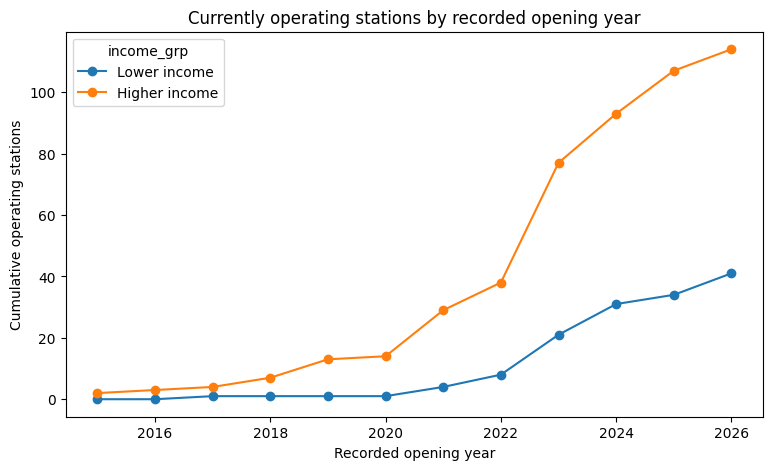

In [4]:
cum = (st.dropna(subset=["open_year"])
         .groupby(["open_year", "income_grp"]).size().unstack(fill_value=0).cumsum())
ax = cum[[c for c in ["Lower income", "Higher income"] if c in cum]].plot(marker="o", figsize=(9, 5))
ax.set_ylabel("Cumulative operating stations"); ax.set_xlabel("Recorded opening year")
ax.set_title("Currently operating stations by recorded opening year")

In [5]:
by_net = st.groupby(["ev_network", "income_grp"]).size().unstack(fill_value=0)
by_net[by_net.sum(axis=1) >= 5]

income_grp,Higher income,Income missing,Lower income
ev_network,,,
Blink Network,6,5,6
ChargePoint Network,73,16,29
Electrify America,4,1,1
FLASH,14,0,1
Tesla,4,1,1
Tesla Destination,3,2,0
eVgo Network,4,0,1
